In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics import silhouette_score
from sklearn.decomposition import TruncatedSVD

from scipy.cluster.hierarchy import dendrogram, linkage

In [ ]:
categories = [
    'comp.graphics',
    'sci.space',
    'rec.sport.baseball',
    'talk.politics.misc'
]

dataset = fetch_20newsgroups(
    subset='all',
    categories=categories,
    remove=('headers', 'footers', 'quotes')
)

documents = dataset.data
true_labels = dataset.target

print("Number of documents:", len(documents))

Number of documents: 3729


In [ ]:
vectorizer = TfidfVectorizer(
    stop_words='english',
    max_features=5000
)

X = vectorizer.fit_transform(documents)

print(X.shape)

(3729, 5000)


In [ ]:
svd = TruncatedSVD(n_components=100, random_state=42)

X_reduced = svd.fit_transform(X)

print(X_reduced.shape)


(3729, 100)


In [ ]:
hc = AgglomerativeClustering(
    n_clusters=4,
    linkage='ward'
)

predicted = hc.fit_predict(X_reduced)

In [ ]:
ari = adjusted_rand_score(true_labels, predicted)

print("Adjusted Rand Index:", ari)

Adjusted Rand Index: 0.21424649080759284


In [ ]:
score = silhouette_score(X_reduced, predicted)

print("Silhouette Score:", score)

Silhouette Score: 0.048564134174282694


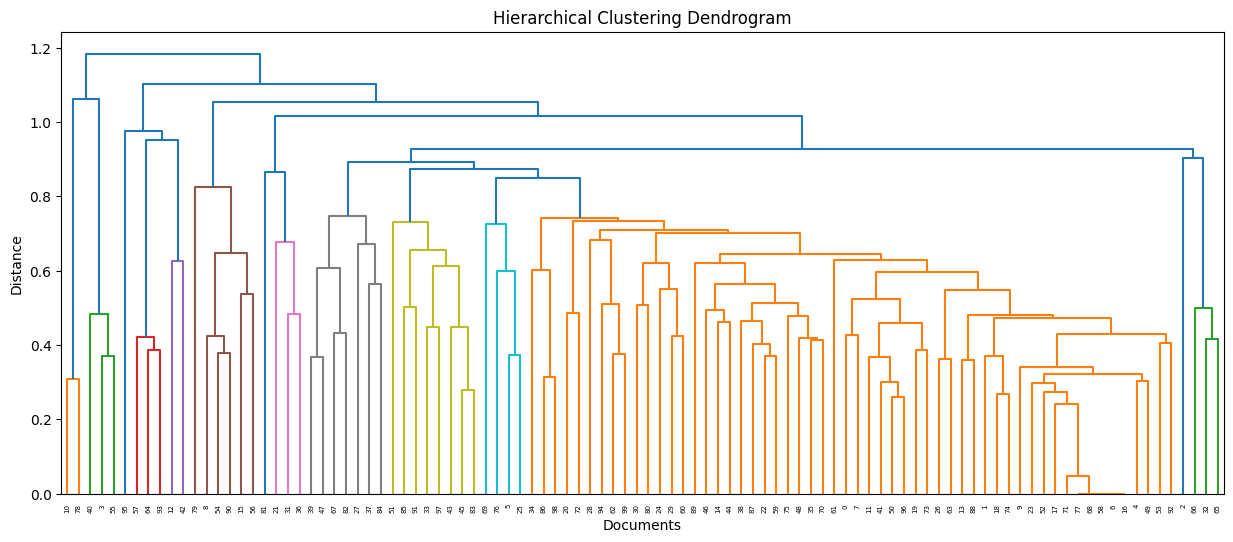

In [ ]:
sample = X_reduced[:100]

Z = linkage(sample, method='ward')

plt.figure(figsize=(15,6))
dendrogram(Z)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Documents")
plt.ylabel("Distance")
plt.show()

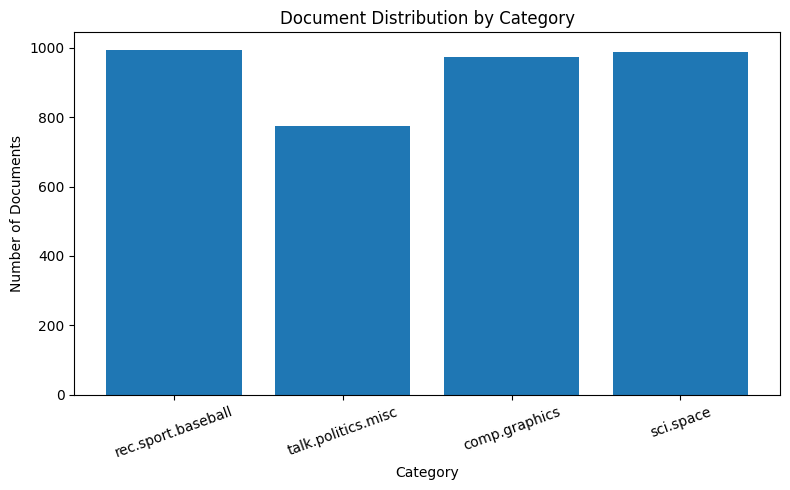

In [ ]:
from collections import Counter
import matplotlib.pyplot as plt

category_names = [dataset.target_names[i] for i in dataset.target]
counts = Counter(category_names)

plt.figure(figsize=(8,5))
plt.bar(counts.keys(), counts.values())
plt.title("Document Distribution by Category")
plt.xlabel("Category")
plt.ylabel("Number of Documents")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
for i in range(4):
    print("="*80)
    print("Category:", dataset.target_names[dataset.target[i]])
    print()
    print(dataset.data[i][:600])      # First 600 characters
    print()

Category: rec.sport.baseball


Are you kidding?  I'm stuck with the Toronto SkyDome, where their idea
of a 7th inning stretch is that "Blue Jays" song where everyone gets
to yell:  "Okay, okay, Blue Jays, Blue Jays, Let's Play Ball!"

Wow.. what genius did it take to compose that one, to outshine the
old classic.  And there are women on the field to "lead the crowd".

Category: talk.politics.misc







Sigh.  You're absolutely right.  We have no political power whatsoever. 
Therefore, we should be oppressed and ignored and denigrated, right?  I
certainly hope you don't have an SO, sir, because if she heard how
disparaging you are towards political minorities, and if she had any shred
of self-respect, she'd be out the door.



Don't count on it, sweetheart.

   ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

Certainly not.  Most major universities wouldn't touch views that display
the brainpower and the perspective of a mayfly with a ten-foot pole.

Drewcifer

P.S.  Incidentally, I think even mayflie

In [ ]:
print("Total Documents :", len(dataset.data))
print("Categories :", dataset.target_names)
print("Vocabulary Size :", len(vectorizer.vocabulary_))
print("TF-IDF Shape :", X.shape)
print("Reduced Shape :", X_reduced.shape)

Total Documents : 3729
Categories : ['comp.graphics', 'rec.sport.baseball', 'sci.space', 'talk.politics.misc']
Vocabulary Size : 5000
TF-IDF Shape : (3729, 5000)
Reduced Shape : (3729, 100)


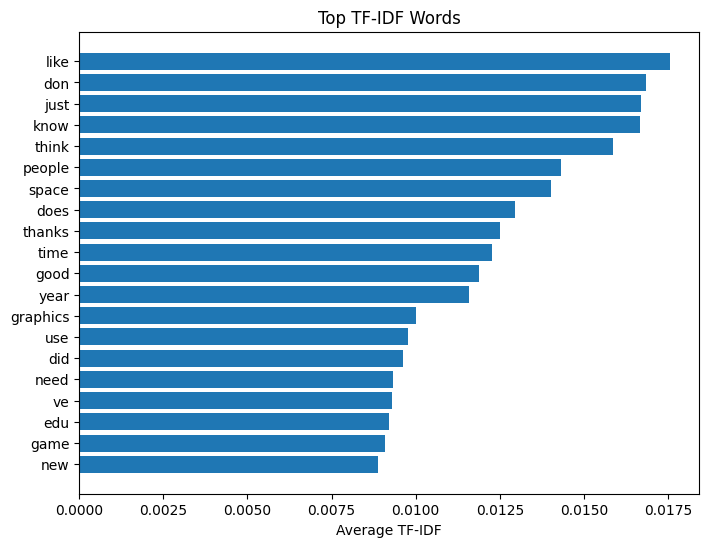

In [ ]:
import numpy as np

mean_tfidf = np.asarray(X.mean(axis=0)).ravel()

indices = np.argsort(mean_tfidf)[::-1][:20]

words = np.array(vectorizer.get_feature_names_out())[indices]

scores = mean_tfidf[indices]

plt.figure(figsize=(8,6))
plt.barh(words[::-1], scores[::-1])
plt.title("Top TF-IDF Words")
plt.xlabel("Average TF-IDF")
plt.show()

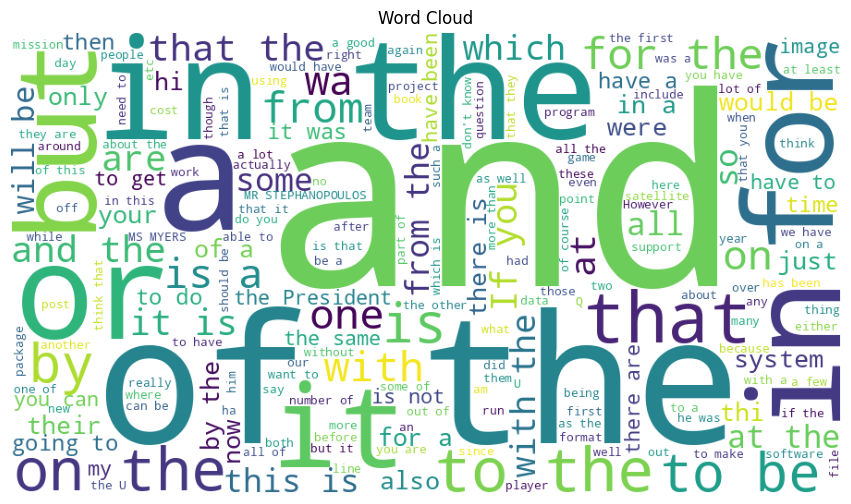

In [ ]:
from wordcloud import WordCloud

text = " ".join(documents)

wc = WordCloud(
    width=900,
    height=500,
    background_color="white",
    stopwords="english"
).generate(text)

plt.figure(figsize=(12,6))
plt.imshow(wc)
plt.axis("off")
plt.title("Word Cloud")
plt.show()

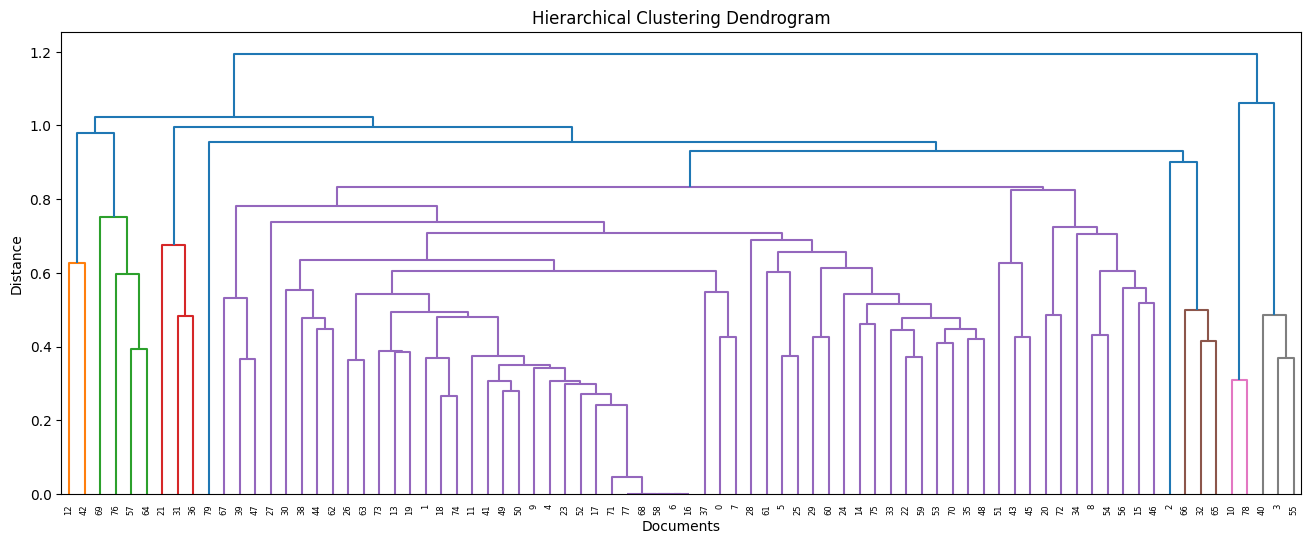

In [ ]:
from scipy.cluster.hierarchy import linkage, dendrogram

sample = X_reduced[:80]

Z = linkage(sample, method="ward")

plt.figure(figsize=(16,6))
dendrogram(Z)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Documents")
plt.ylabel("Distance")
plt.show()

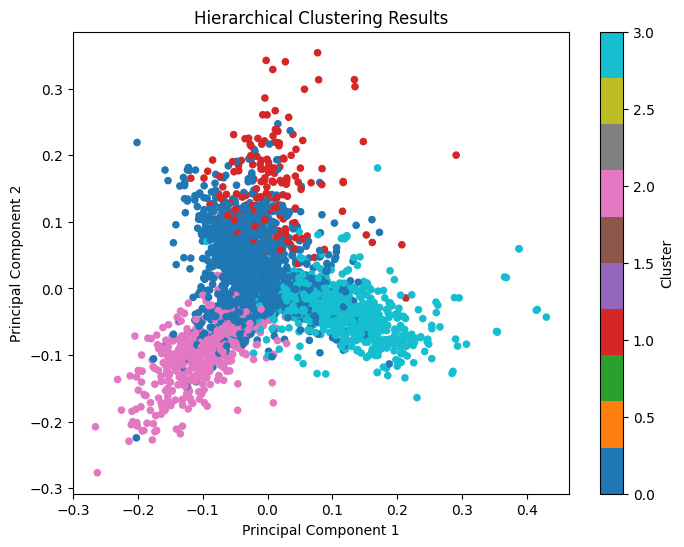

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_reduced)

plt.figure(figsize=(8,6))

plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    c=predicted,
    cmap="tab10",
    s=20
)

plt.title("Hierarchical Clustering Results")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")
plt.show()

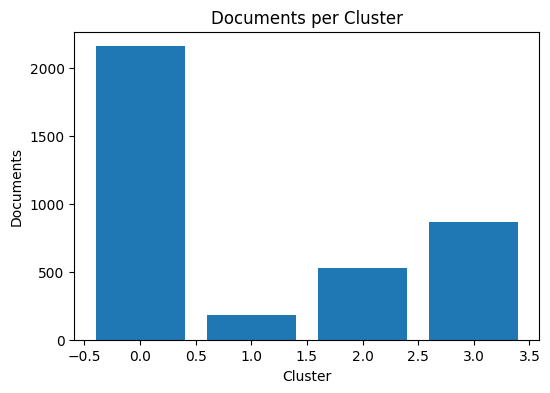

In [ ]:
from collections import Counter

cluster_count = Counter(predicted)

plt.figure(figsize=(6,4))
plt.bar(cluster_count.keys(), cluster_count.values())
plt.xlabel("Cluster")
plt.ylabel("Documents")
plt.title("Documents per Cluster")
plt.show()

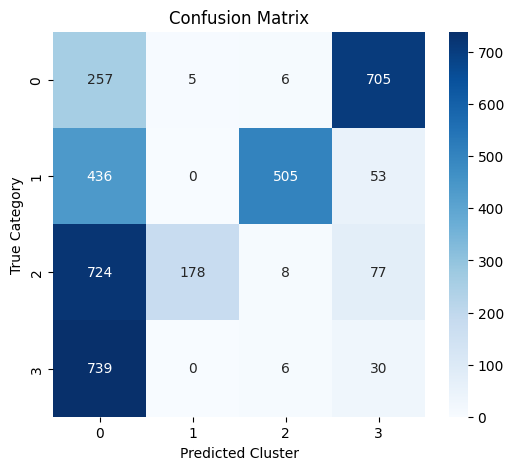

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(true_labels, predicted)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted Cluster")
plt.ylabel("True Category")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
from sklearn.metrics import silhouette_score

score = silhouette_score(X_reduced, predicted)

print("Silhouette Score =", score)

Silhouette Score = 0.048564134174282694


In [ ]:
from sklearn.metrics import adjusted_rand_score

ari = adjusted_rand_score(true_labels, predicted)

print("Adjusted Rand Index =", ari)

Adjusted Rand Index = 0.21424649080759284


In [ ]:
import numpy as np

terms = vectorizer.get_feature_names_out()

for cluster in range(4):

    docs = X[predicted == cluster]

    mean = np.asarray(docs.mean(axis=0)).ravel()

    top = mean.argsort()[-10:][::-1]

    print("\nCluster", cluster)
    print("----------------------")

    for i in top:
        print(terms[i])


Cluster 0
----------------------
just
people
like
don
think
know
time
good
did
new

Cluster 1
----------------------
space
nasa
station
sci
gov
ames
don
people
program
world

Cluster 2
----------------------
game
year
team
games
baseball
hit
runs
think
braves
players

Cluster 3
----------------------
thanks
graphics
does
image
files
file
know
program
format
software


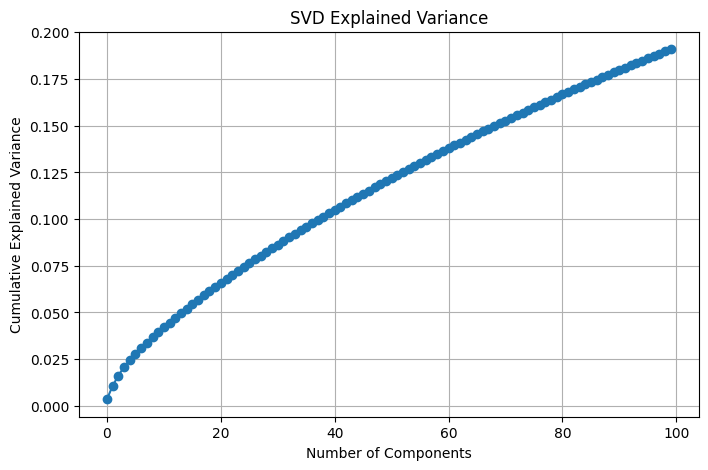

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    np.cumsum(svd.explained_variance_ratio_),
    marker='o'
)

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("SVD Explained Variance")
plt.grid(True)
plt.show()

In [ ]:
for i in range(4):

    print("="*40)

    print("Cluster", i)

    print("Documents :", np.sum(predicted==i))

Cluster 0
Documents : 2156
Cluster 1
Documents : 183
Cluster 2
Documents : 525
Cluster 3
Documents : 865
